# Heart Disease UCI — Complete Pipeline
Cleaning → EDA Plots → Feature Engineering → Multiclass Models (SVM, RF, MLP) + GridSearchCV

## 1. Importing Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, ConfusionMatrixDisplay)

SEED = 42

## 2. Importing Dataset

In [2]:
df = pd.read_csv("heart_disease_uci.csv")
print(df.head())

   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defect    0  
1             normal    2  
2  reversable defect    1  
3             normal    0  
4             normal    0  


## 3. Analyzing Dataset

In [3]:
print(df.info())
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB
None


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
count,920.000000,920.000000,920,920,920,861.000000,890.000000,830,918,865.000000,865,858.000000,611,309.000000,434,920.000000
unique,NaN,NaN,2,4,4,NaN,NaN,2,3,NaN,2,NaN,3,NaN,3,NaN
top,NaN,NaN,Male,Cleveland,asymptomatic,NaN,NaN,False,normal,NaN,False,NaN,flat,NaN,normal,NaN
freq,NaN,NaN,726,304,496,NaN,NaN,692,551,NaN,528,NaN,345,NaN,196,NaN
mean,460.500000,53.510870,NaN,NaN,NaN,132.132404,199.130337,NaN,NaN,137.545665,NaN,0.878788,NaN,0.676375,NaN,0.995652
std,265.725422,9.424685,NaN,NaN,NaN,19.066070,110.780810,NaN,NaN,25.926276,NaN,1.091226,NaN,0.935653,NaN,1.142693
min,1.000000,28.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,60.000000,NaN,-2.600000,NaN,0.000000,NaN,0.000000
25%,230.750000,47.000000,NaN,NaN,NaN,120.000000,175.000000,NaN,NaN,120.000000,NaN,0.000000,NaN,0.000000,NaN,0.000000
50%,460.500000,54.000000,NaN,NaN,NaN,130.000000,223.000000,NaN,NaN,140.000000,NaN,0.500000,NaN,0.000000,NaN,1.000000
75%,690.250000,60.000000,NaN,NaN,NaN,140.000000,268.000000,NaN,NaN,157.000000,NaN,1.500000,NaN,1.000000,NaN,2.000000


## 4. Handle Missing Values

In [4]:
print(df.isnull().sum())

# numerical columns
num_cols = df.select_dtypes(include=['float64', 'int64']).columns

# categorical columns
cat_cols = df.select_dtypes(include=['object']).columns

# fill missing values safely
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


## 5. Remove Duplicates

In [5]:
df.drop_duplicates(inplace=True)

## 6. Handle Outliers

### 6a. Visualize Outliers with Boxplots

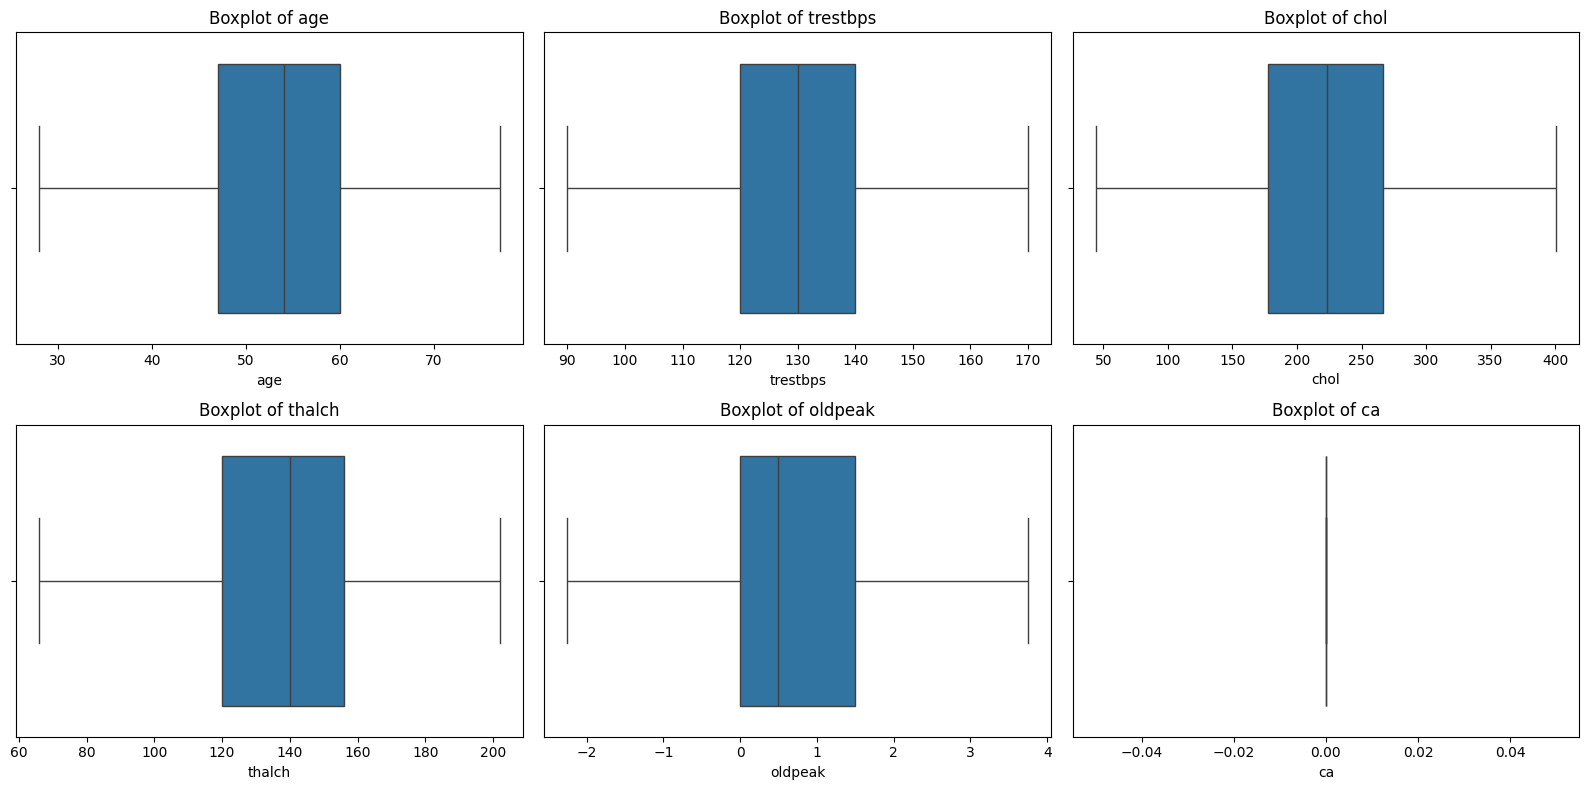

In [24]:
n_cols = len(num_cols)
n_rows = (n_cols + 2) // 3  # 3 plots per row
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4*n_rows))
axes = axes.flatten()  # Flatten to 1D array for easier indexing

for idx, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[idx])
    axes[idx].set_title(f'Boxplot of {col}')

# Hide unused subplots
for idx in range(len(num_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

### 6b. IQR Clipping for Outliers

In [25]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower, lower,
               np.where(df[col] > upper, upper, df[col]))

## 7. Univariate Analysis

### 7a. Distribution of Numerical Features

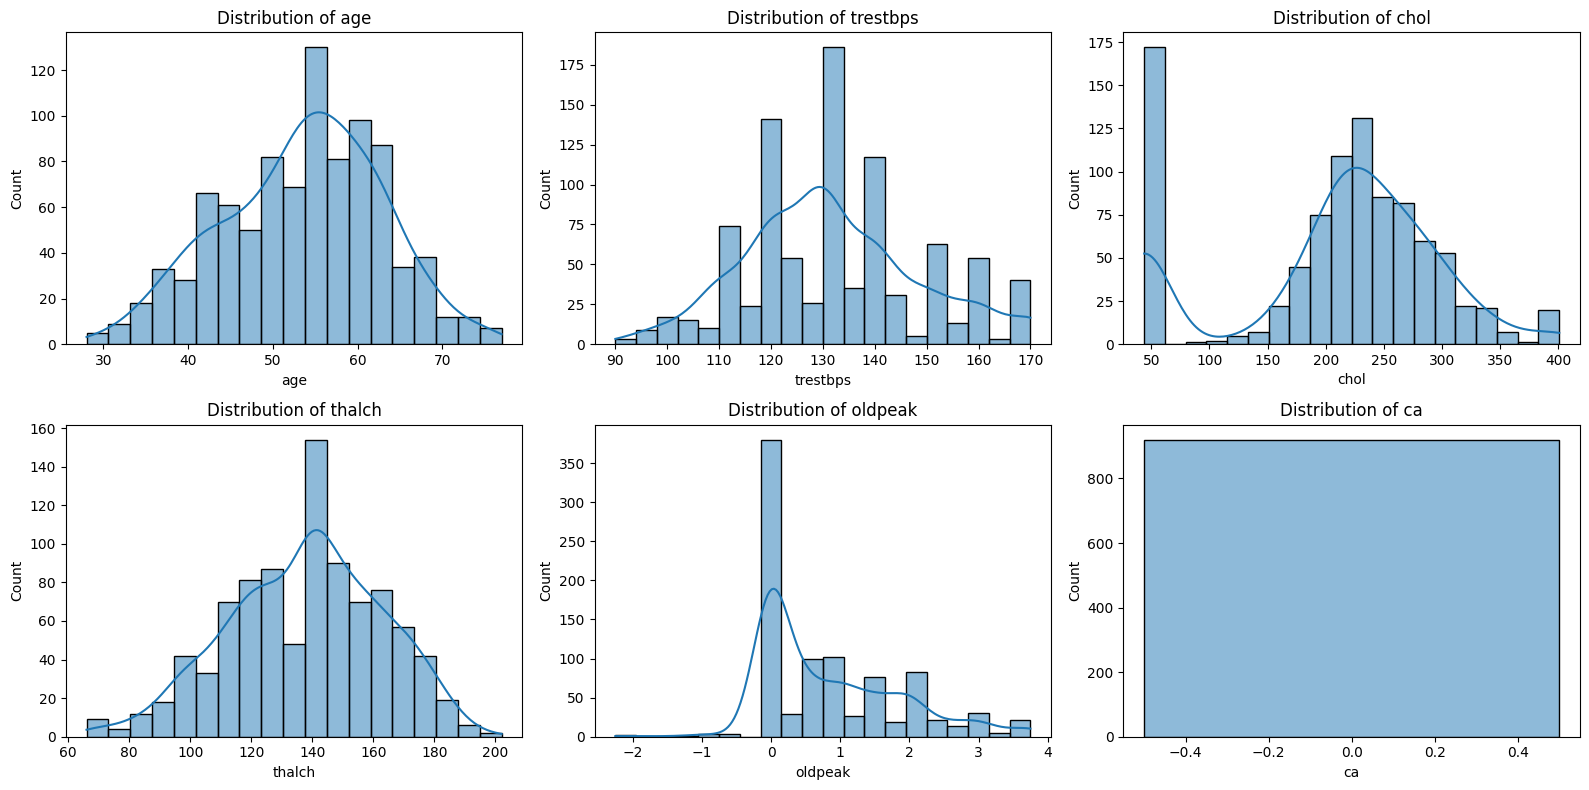

In [26]:
n_cols = len(num_cols)
n_rows = (n_cols + 2) // 3  # 3 plots per row
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4*n_rows))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[idx])
    axes[idx].set_title(f'Distribution of {col}')

# Hide unused subplots
for idx in range(len(num_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

### 7b. Count of Categorical Features

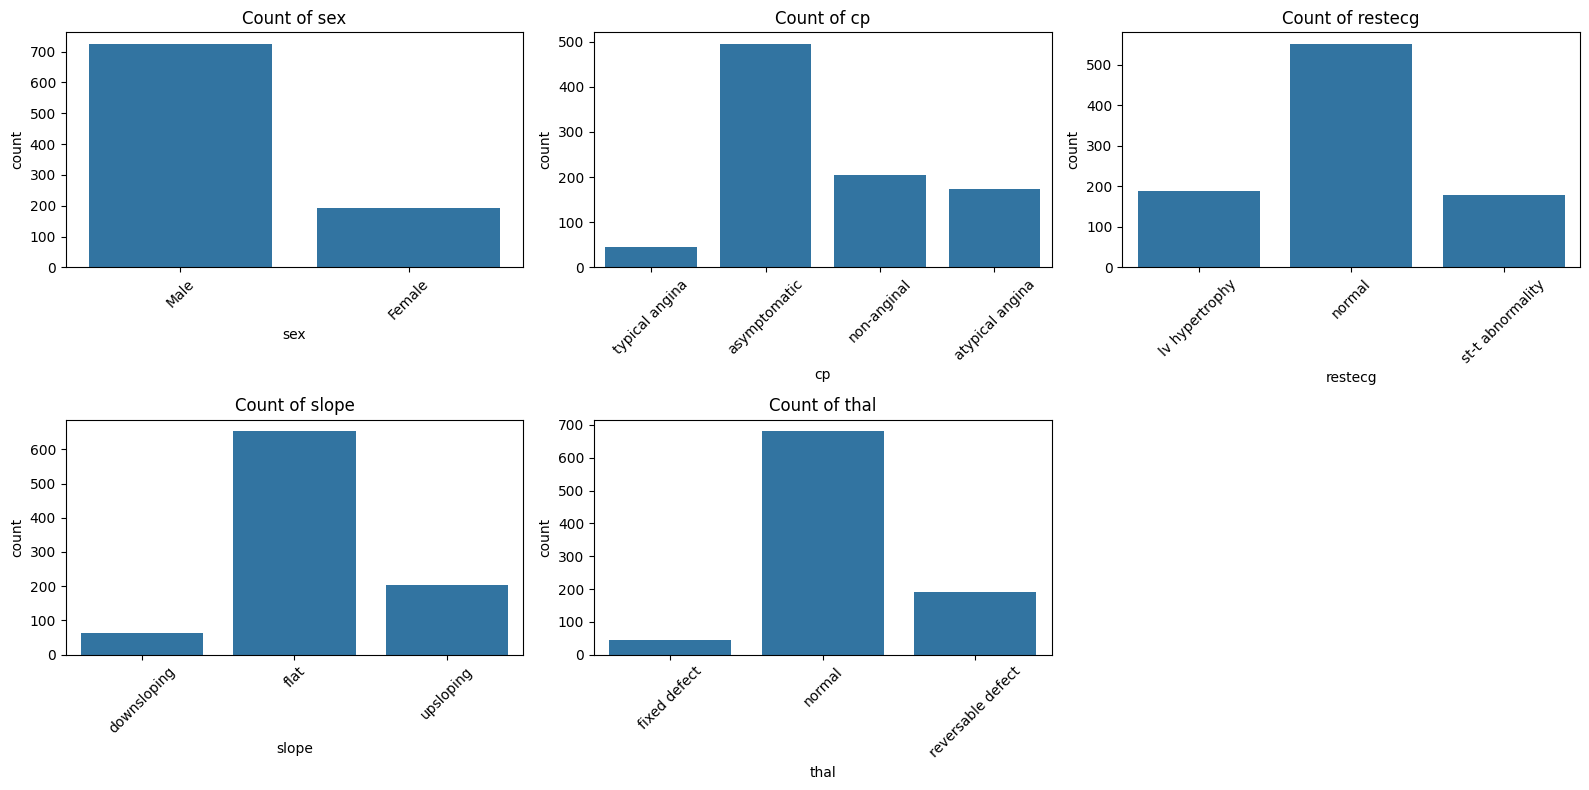

In [27]:
n_cat = len(cat_cols)
n_rows = (n_cat + 2) // 3  # 3 plots per row
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4*n_rows))
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    sns.countplot(x=df[col], ax=axes[idx])
    axes[idx].set_title(f'Count of {col}')
    axes[idx].tick_params(axis='x', rotation=45)

# Hide unused subplots
for idx in range(len(cat_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

## 8. Bivariate Analysis

### 8a. Numerical Features vs Target

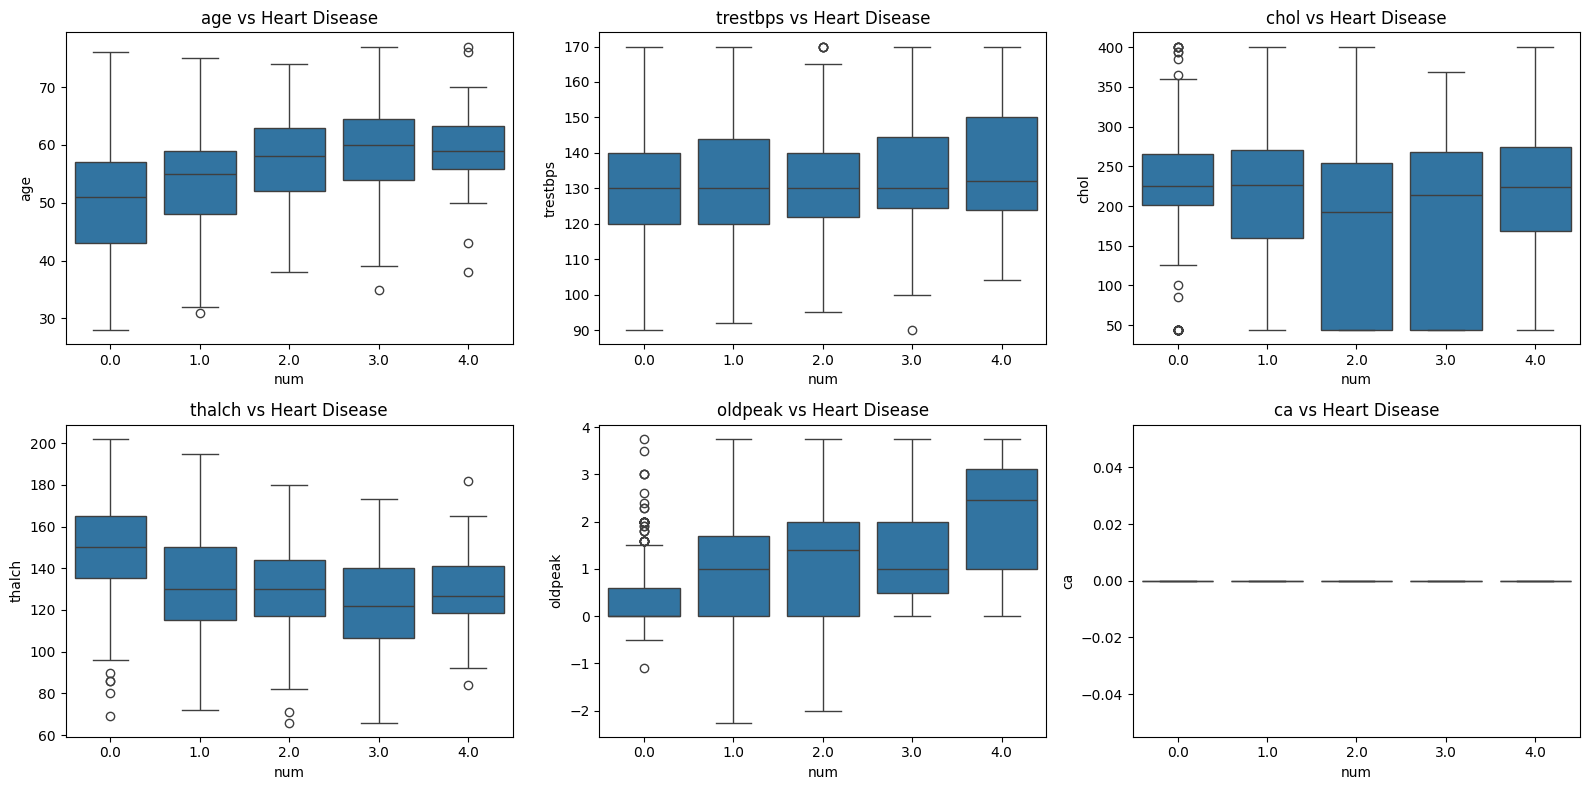

In [28]:
n_cols = len(num_cols)
n_rows = (n_cols + 2) // 3  # 3 plots per row
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4*n_rows))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.boxplot(x=df['num'], y=df[col], ax=axes[idx])
    axes[idx].set_title(f'{col} vs Heart Disease')

# Hide unused subplots
for idx in range(len(num_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

### 8b. Categorical Features vs Target

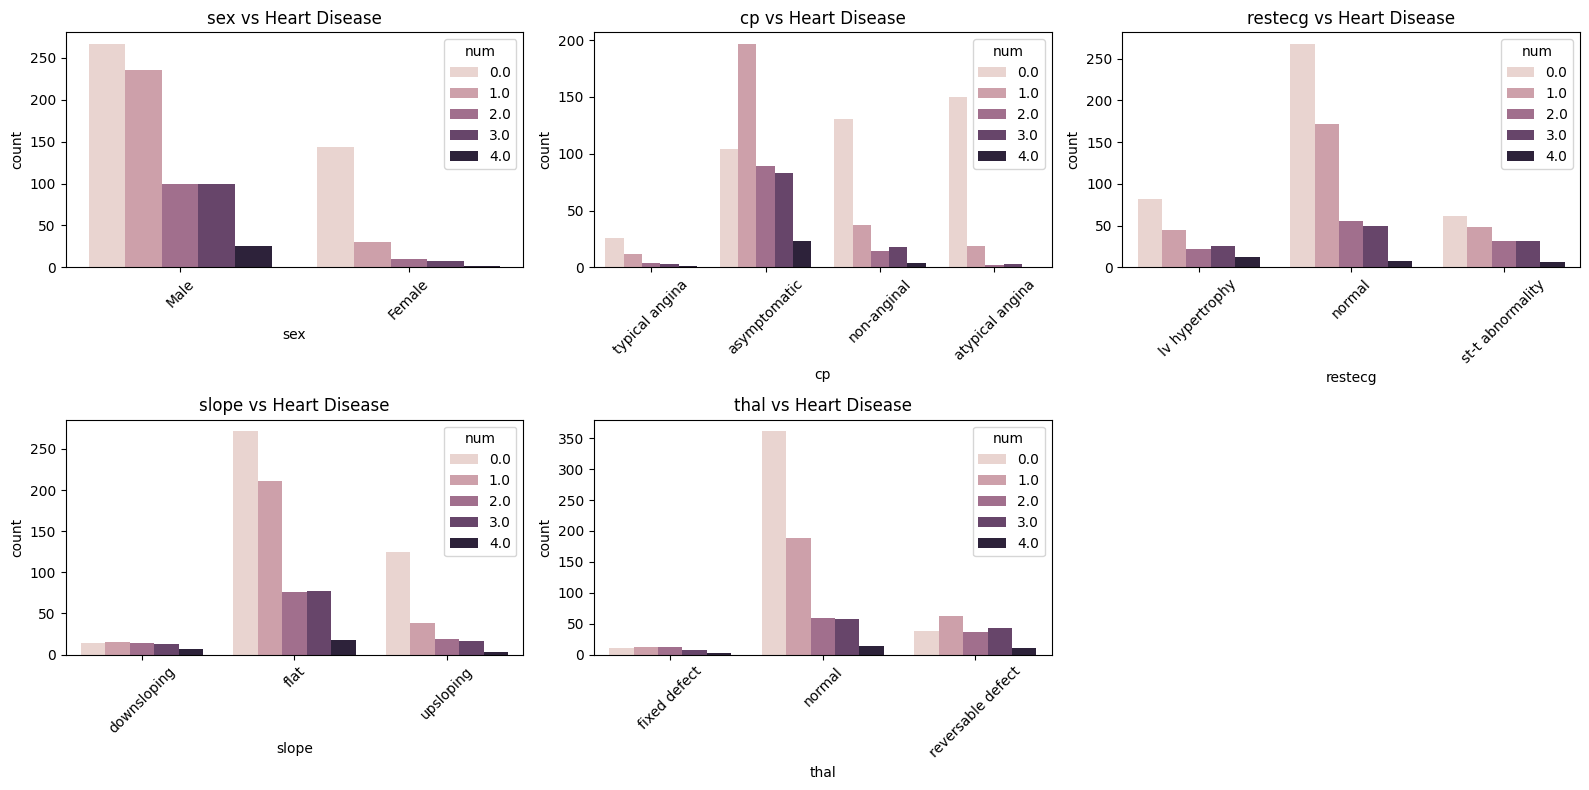

In [29]:
n_cat = len(cat_cols)
n_rows = (n_cat + 2) // 3  # 3 plots per row
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4*n_rows))
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    sns.countplot(x=df[col], hue=df['num'], ax=axes[idx])
    axes[idx].set_title(f'{col} vs Heart Disease')
    axes[idx].tick_params(axis='x', rotation=45)

# Hide unused subplots
for idx in range(len(cat_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

### 8c. Correlation Heatmap

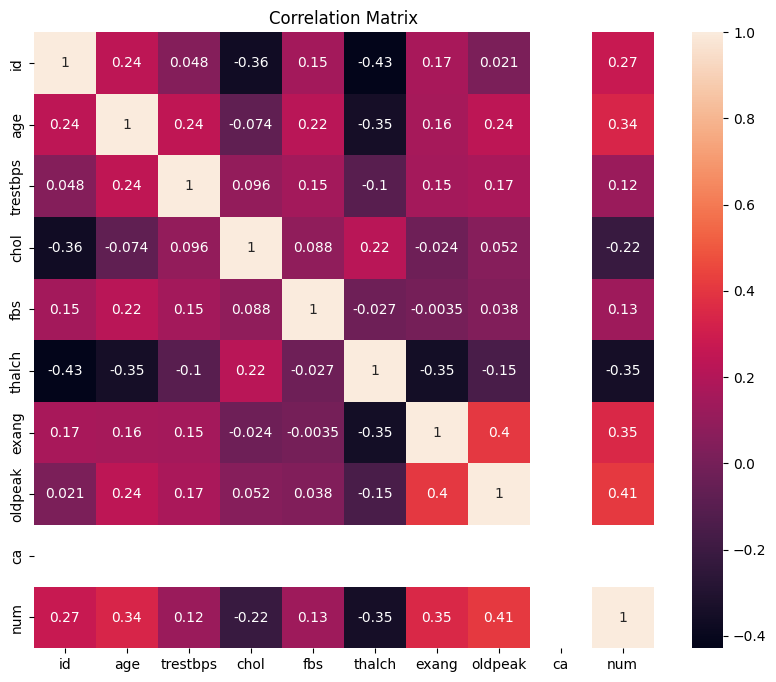

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.title("Correlation Matrix")
plt.show()

### 8d. Pair Plot

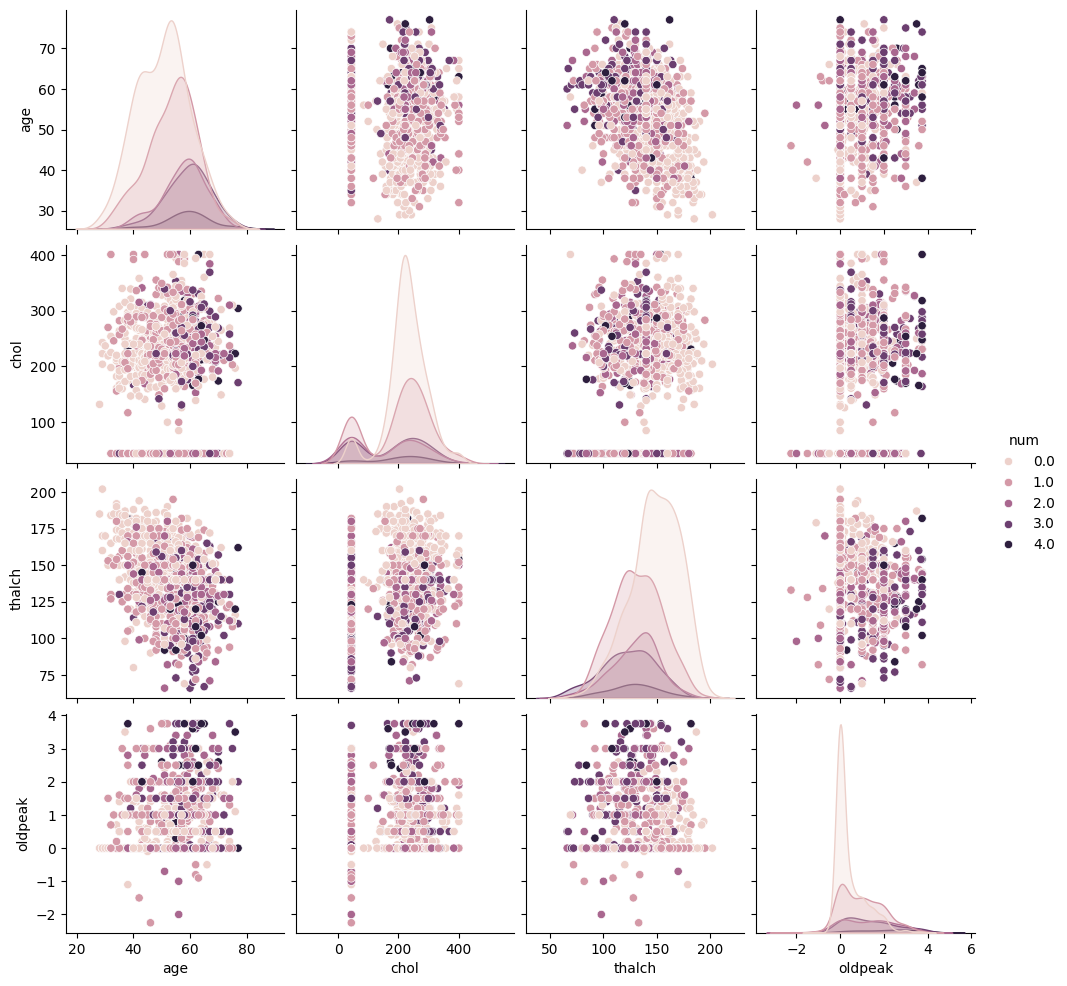

In [13]:
sns.pairplot(df[['age', 'chol', 'thalch', 'oldpeak', 'num']], hue='num')
plt.show()

## 9. Feature Engineering

In [14]:
print("\n--- Feature Engineering ---")

# Drop non-predictive columns if present
df.drop(columns=[c for c in ['id', 'dataset'] if c in df.columns], inplace=True)

# Re-derive column type lists after dropping
num_cols = [c for c in df.select_dtypes(include=['float64', 'int64']).columns if c != 'num']
cat_cols  = df.select_dtypes(include=['object']).columns.tolist()

# --- 9a. Age Group Binning ---
# Groups continuous age into clinically meaningful brackets.
# Captures the non-linear relationship between age and heart disease risk.
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 40, 50, 60, 100],
    labels=['<40', '40-50', '50-60', '60+']
)

# --- 9b. Cholesterol Risk Flag ---
# Binary flag: cholesterol > 200 mg/dL is the standard clinical threshold
# for elevated cardiovascular risk.
df['chol_risk'] = (df['chol'] > 200).astype(int)

# --- 9c. High Max Heart Rate Flag ---
# Patients above the mean thalch have better cardiovascular fitness;
# below-average thalch is associated with higher disease severity.
df['high_thalch'] = (df['thalch'] > df['thalch'].mean()).astype(int)

# --- 9d. Age-to-Thalch Interaction Feature ---
# Older age combined with lower max heart rate indicates higher risk.
# This ratio captures that joint effect in a single numeric feature.
df['age_thalch_ratio'] = df['age'] / (df['thalch'] + 1)

# --- 9e. Oldpeak Severity Binning ---
# Bins ST depression (oldpeak) into clinically labelled severity levels,
# aligning the feature with standard ECG interpretation guidelines.
df['oldpeak_cat'] = pd.cut(
    df['oldpeak'],
    bins=[-0.1, 0, 1, 2, 10],
    labels=['none', 'mild', 'moderate', 'severe']
)

print("New features: age_group, chol_risk, high_thalch, age_thalch_ratio, oldpeak_cat")
print(df[['age_group', 'chol_risk', 'high_thalch', 'age_thalch_ratio', 'oldpeak_cat']].head())


--- Feature Engineering ---
New features: age_group, chol_risk, high_thalch, age_thalch_ratio, oldpeak_cat
  age_group  chol_risk  high_thalch  age_thalch_ratio oldpeak_cat
0       60+          1            1          0.417219      severe
1       60+          1            0          0.614679    moderate
2       60+          1            0          0.515385      severe
3       <40          1            1          0.196809      severe
4     40-50          1            1          0.236994    moderate


### 9f. Visualize Engineered Features

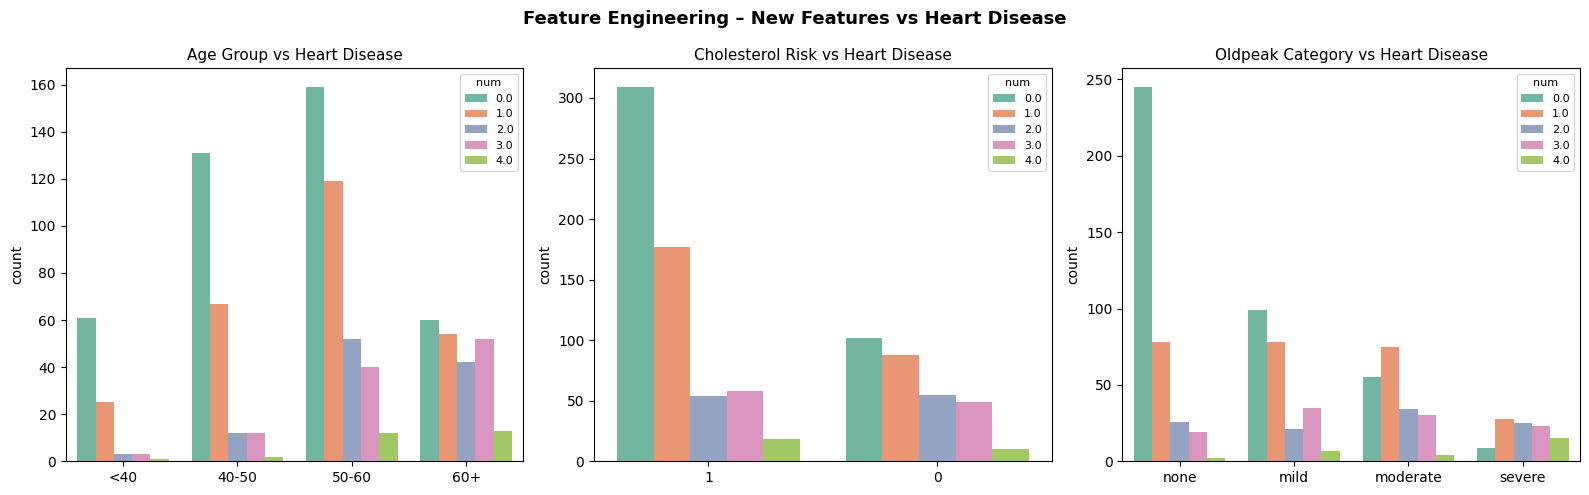

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Feature Engineering – New Features vs Heart Disease", fontsize=13, fontweight='bold')

for ax, col, title in zip(
    axes,
    ['age_group', 'chol_risk', 'oldpeak_cat'],
    ['Age Group vs Heart Disease', 'Cholesterol Risk vs Heart Disease', 'Oldpeak Category vs Heart Disease']
):
    order = df[col].cat.categories if hasattr(df[col], 'cat') else df[col].value_counts().index
    sns.countplot(x=col, hue='num', data=df, ax=ax, order=order, palette='Set2')
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('')
    ax.legend(title='num', fontsize=8, title_fontsize=8)

plt.tight_layout()
plt.show()

## 10. Data Preparation for Modelling

In [16]:
df_model = df.copy()

# Label-encode all categorical / ordinal columns
le = LabelEncoder()
encode_cols = df_model.select_dtypes(include=['object', 'category']).columns.tolist()
for col in encode_cols:
    df_model[col] = le.fit_transform(df_model[col].astype(str))

X = df_model.drop(columns=['num'])
y = df_model['num']

# StandardScaler — essential for SVM and MLP
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"\nTrain : {X_train.shape}  |  Test : {X_test.shape}")
print("Classes:", sorted(y.unique()))

# 5-fold Stratified CV (preserves class proportions in every fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


Train : (736, 18)  |  Test : (184, 18)
Classes: [0.0, 1.0, 2.0, 3.0, 4.0]


## 11. Multiclass Classification + Hyperparameter Tuning

### 11a. Support Vector Machine (SVM)

In [17]:
print("\n[1/3] SVM — GridSearchCV")

svm_param_grid = {
    'C'      : [0.1, 1, 10],        # Regularisation strength
    'kernel' : ['rbf', 'linear'],   # Kernel type
    'gamma'  : ['scale', 'auto']    # Kernel coefficient (rbf only)
}

svm_grid = GridSearchCV(
    estimator  = SVC(random_state=SEED, probability=True),
    param_grid = svm_param_grid,
    cv         = cv,
    scoring    = 'accuracy',
    n_jobs     = -1,
    verbose    = 1
)
svm_grid.fit(X_train, y_train)
svm_pred = svm_grid.predict(X_test)

results = {}
results['SVM'] = {
    'best_params'  : svm_grid.best_params_,
    'cv_accuracy'  : svm_grid.best_score_,
    'test_accuracy': accuracy_score(y_test, svm_pred),
    'predictions'  : svm_pred
}
print(f"  Best Params   : {svm_grid.best_params_}")
print(f"  CV Accuracy   : {svm_grid.best_score_:.4f}")
print(f"  Test Accuracy : {results['SVM']['test_accuracy']:.4f}")


[1/3] SVM — GridSearchCV
Fitting 5 folds for each of 12 candidates, totalling 60 fits
  Best Params   : {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
  CV Accuracy   : 0.5748
  Test Accuracy : 0.5598


### 11b. Random Forest

In [18]:
print("\n[2/3] Random Forest — GridSearchCV")

rf_param_grid = {
    'n_estimators'    : [100, 200],      # Number of trees
    'max_depth'       : [None, 10, 20],  # Maximum tree depth
    'min_samples_split': [2, 5]          # Min samples to split a node
}

rf_grid = GridSearchCV(
    estimator  = RandomForestClassifier(random_state=SEED),
    param_grid = rf_param_grid,
    cv         = cv,
    scoring    = 'accuracy',
    n_jobs     = -1,
    verbose    = 1
)
rf_grid.fit(X_train, y_train)
rf_pred = rf_grid.predict(X_test)

results['Random Forest'] = {
    'best_params'  : rf_grid.best_params_,
    'cv_accuracy'  : rf_grid.best_score_,
    'test_accuracy': accuracy_score(y_test, rf_pred),
    'predictions'  : rf_pred
}
print(f"  Best Params   : {rf_grid.best_params_}")
print(f"  CV Accuracy   : {rf_grid.best_score_:.4f}")
print(f"  Test Accuracy : {results['Random Forest']['test_accuracy']:.4f}")


[2/3] Random Forest — GridSearchCV
Fitting 5 folds for each of 12 candidates, totalling 60 fits
  Best Params   : {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
  CV Accuracy   : 0.5816
  Test Accuracy : 0.5652


### 11c. MLP Neural Network

In [19]:
print("\n[3/3] MLP Neural Network — GridSearchCV")

mlp_param_grid = {
    'hidden_layer_sizes': [(64, 32), (128, 64)],   # Network architecture
    'activation'        : ['relu', 'tanh'],         # Activation function
    'alpha'             : [0.0001, 0.001],          # L2 regularisation
    'max_iter'          : [500]
}

mlp_grid = GridSearchCV(
    estimator  = MLPClassifier(random_state=SEED, early_stopping=True),
    param_grid = mlp_param_grid,
    cv         = cv,
    scoring    = 'accuracy',
    n_jobs     = -1,
    verbose    = 1
)
mlp_grid.fit(X_train, y_train)
mlp_pred = mlp_grid.predict(X_test)

results['MLP'] = {
    'best_params'  : mlp_grid.best_params_,
    'cv_accuracy'  : mlp_grid.best_score_,
    'test_accuracy': accuracy_score(y_test, mlp_pred),
    'predictions'  : mlp_pred
}
print(f"  Best Params   : {mlp_grid.best_params_}")
print(f"  CV Accuracy   : {mlp_grid.best_score_:.4f}")
print(f"  Test Accuracy : {results['MLP']['test_accuracy']:.4f}")


[3/3] MLP Neural Network — GridSearchCV
Fitting 5 folds for each of 8 candidates, totalling 40 fits
  Best Params   : {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (128, 64), 'max_iter': 500}
  CV Accuracy   : 0.5531
  Test Accuracy : 0.5924


## 12. Model Evaluation

### 12a. Classification Reports

In [20]:
for name, res in results.items():
    print(f"\n--- {name} Classification Report ---")
    print(classification_report(y_test, res['predictions'], zero_division=0))


--- SVM Classification Report ---
              precision    recall  f1-score   support

         0.0       0.75      0.88      0.81        82
         1.0       0.44      0.57      0.50        53
         2.0       0.00      0.00      0.00        22
         3.0       0.06      0.05      0.05        21
         4.0       0.00      0.00      0.00         6

    accuracy                           0.56       184
   macro avg       0.25      0.30      0.27       184
weighted avg       0.47      0.56      0.51       184


--- Random Forest Classification Report ---
              precision    recall  f1-score   support

         0.0       0.73      0.84      0.78        82
         1.0       0.46      0.57      0.51        53
         2.0       0.18      0.09      0.12        22
         3.0       0.23      0.14      0.18        21
         4.0       0.00      0.00      0.00         6

    accuracy                           0.57       184
   macro avg       0.32      0.33      0.32       1

### 12b. Confusion Matrices

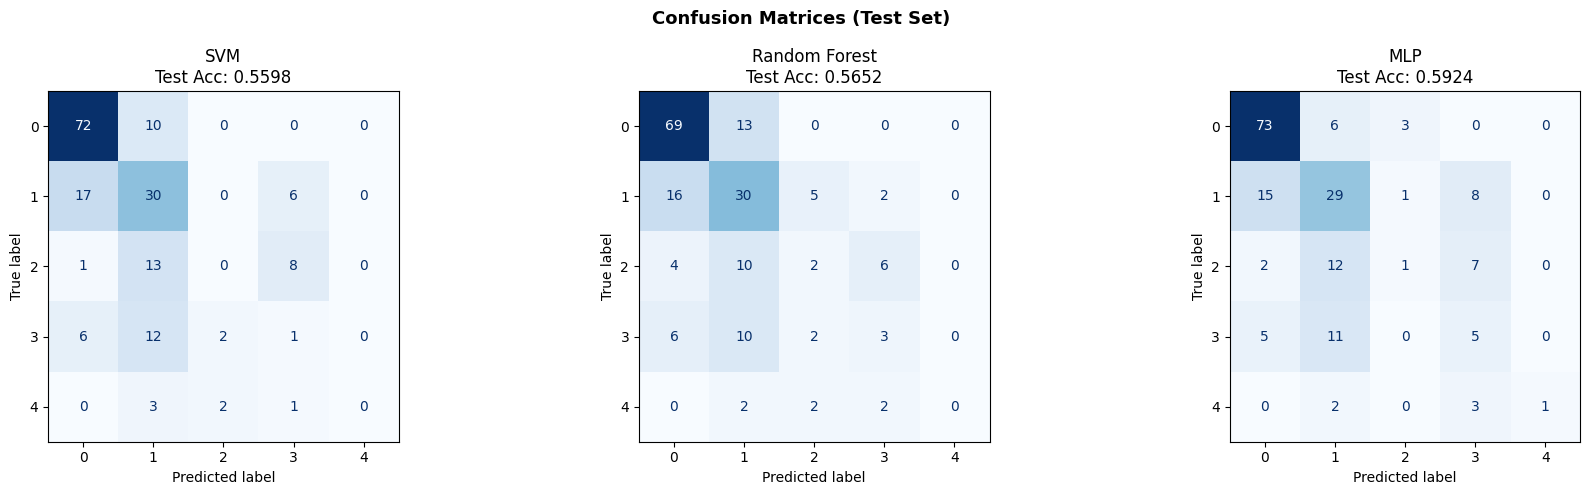

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Confusion Matrices (Test Set)", fontsize=13, fontweight='bold')
for ax, (name, res) in zip(axes, results.items()):
    cm   = confusion_matrix(y_test, res['predictions'])
    disp = ConfusionMatrixDisplay(cm, display_labels=[0, 1, 2, 3, 4])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f"{name}\nTest Acc: {res['test_accuracy']:.4f}")
plt.tight_layout()
plt.show()

### 12c. Model Comparison & Feature Importance

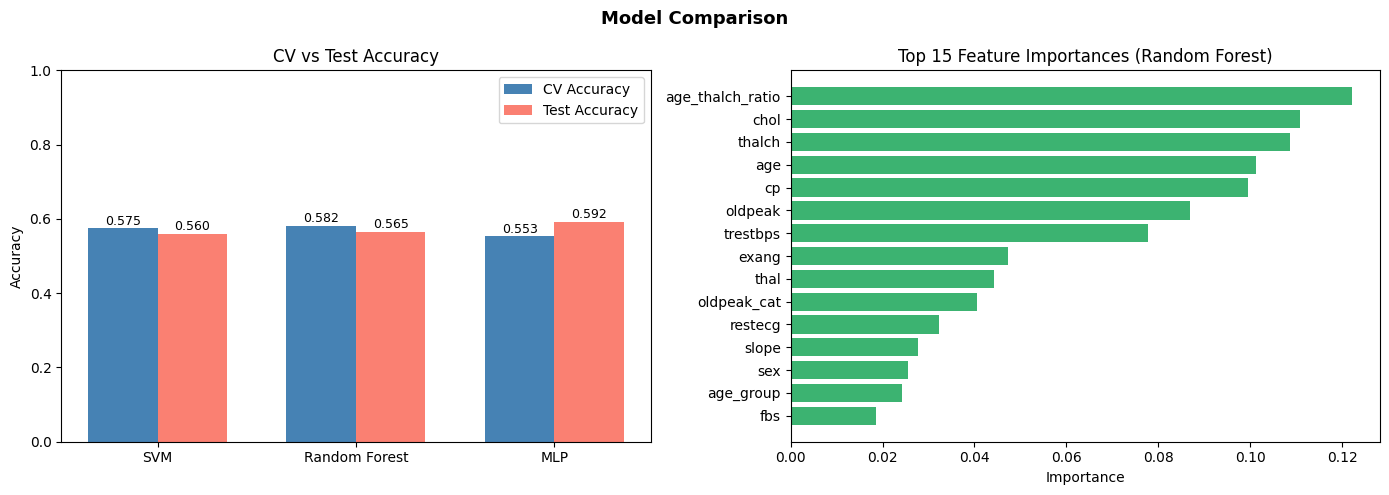

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Model Comparison", fontsize=13, fontweight='bold')

names       = list(results.keys())
cv_scores   = [results[n]['cv_accuracy']   for n in names]
test_scores = [results[n]['test_accuracy'] for n in names]
x, w = np.arange(len(names)), 0.35

axes[0].bar(x - w/2, cv_scores,   w, label='CV Accuracy',   color='steelblue')
axes[0].bar(x + w/2, test_scores, w, label='Test Accuracy', color='salmon')
axes[0].set_xticks(x)
axes[0].set_xticklabels(names)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Accuracy')
axes[0].set_title('CV vs Test Accuracy')
axes[0].legend()
for i, (cv, te) in enumerate(zip(cv_scores, test_scores)):
    axes[0].text(i - w/2, cv + 0.01, f'{cv:.3f}', ha='center', fontsize=9)
    axes[0].text(i + w/2, te + 0.01, f'{te:.3f}', ha='center', fontsize=9)

# --- Feature Importances (Random Forest) ---
feat_names  = X.columns.tolist()
importances = rf_grid.best_estimator_.feature_importances_
sorted_idx  = np.argsort(importances)[-15:]
axes[1].barh([feat_names[i] for i in sorted_idx], importances[sorted_idx], color='mediumseagreen')
axes[1].set_title('Top 15 Feature Importances (Random Forest)')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

## 13. Final Summary

In [23]:
print("\n" + "="*60)
print("  FINAL SUMMARY")
print("="*60)
summary = pd.DataFrame([{
    'Model'        : name,
    'CV Accuracy'  : f"{res['cv_accuracy']:.4f}",
    'Test Accuracy': f"{res['test_accuracy']:.4f}",
    'Best Params'  : res['best_params']
} for name, res in results.items()])
print(summary.to_string(index=False))


  FINAL SUMMARY
        Model CV Accuracy Test Accuracy                                                                               Best Params
          SVM      0.5748        0.5598                                               {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Random Forest      0.5816        0.5652                            {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
          MLP      0.5531        0.5924 {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (128, 64), 'max_iter': 500}
